# Unit 4: Memvalidasi Data
**Kode unit:** J.62DMI00.006.1 · SKKNI No. 299 Tahun 2020 · Proyek: *Prediksi Arah Harian IHSG*

**Tujuan unit ini:** memeriksa kualitas data sebelum dipakai.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

In [2]:
df = pd.read_csv('../data/raw/market_data.csv', parse_dates=['Date'])

## Cek 1 — Apakah ada data kosong?

In [3]:
kosong = df.isnull().sum()
print(kosong)
df[df.isnull().any(axis=1)]

Date     0
OIL      1
GOLD     1
SP500    1
IHSG     1
VIX      1
dtype: int64


,Date,OIL,GOLD,SP500,IHSG,VIX
0,2010-01-01,NaN,NaN,NaN,NaN,NaN


## Cek 2 — Apakah ada tanggal ganda?

In [4]:
print('Jumlah tanggal ganda:', df['Date'].duplicated().sum())

Jumlah tanggal ganda: 0


## Cek 3 — Apakah ada nilai yang tidak masuk akal (harga ≤ 0)?

In [5]:
for k in ['IHSG', 'SP500', 'OIL', 'GOLD', 'VIX']:
    salah = df[df[k] <= 0]
    if len(salah) > 0:
        print(k, '→', salah[['Date', k]].to_string(index=False))

OIL →       Date        OIL
2020-04-20 -37.630001


Harga minyak **−37,63 USD** pada 20 April 2020 memang pernah terjadi (kontrak minyak AS saat itu), tetapi nilai
negatif membuat perhitungan persentase perubahan menjadi kacau. Nilai ini akan diperbaiki di Unit 6.

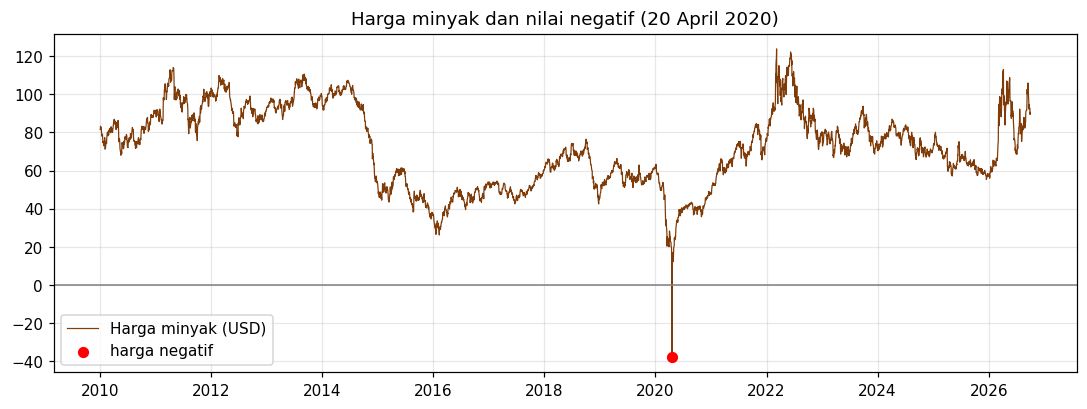

In [6]:
negatif = df['OIL'] <= 0
plt.figure(figsize=(12, 4))
plt.plot(df['Date'], df['OIL'], linewidth=0.8, color='#7f3b08', label='Harga minyak (USD)')
plt.scatter(df.loc[negatif, 'Date'], df.loc[negatif, 'OIL'], color='red', s=40, zorder=3, label='harga negatif')
plt.axhline(0, color='grey', linewidth=1)
plt.title('Harga minyak dan nilai negatif (20 April 2020)')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('../figures/04_minyak_negatif.png', dpi=150, bbox_inches='tight')
plt.show()

## Cek 4 — Apakah semua baris adalah hari bursa BEI?
Pada hari libur BEI (misalnya Lebaran), nilai IHSG hanya **disalin** dari hari sebelumnya sehingga terlihat tidak berubah.

In [7]:
libur = df['IHSG'].diff() == 0
print('Jumlah hari IHSG tidak berubah (libur BEI):', libur.sum())
print('Contoh Lebaran 2010:', df.loc[libur & (df['Date'].dt.year == 2010) & (df['Date'].dt.month == 9), 'Date'].dt.date.tolist())

Jumlah hari IHSG tidak berubah (libur BEI): 304
Contoh Lebaran 2010: [datetime.date(2010, 9, 8), datetime.date(2010, 9, 9), datetime.date(2010, 9, 10), datetime.date(2010, 9, 13), datetime.date(2010, 9, 14)]


## Ringkasan hasil validasi

| No | Masalah | Jumlah | Tindakan (Unit 6) |
|---|---|---|---|
| 1 | Baris kosong (1 Jan 2010, libur Tahun Baru) | 1 baris | Dihapus |
| 2 | Tanggal ganda | 0 | – |
| 3 | Harga minyak negatif | 1 nilai | Diganti nilai hari sebelumnya |
| 4 | Hari libur BEI (IHSG disalin) | 304 baris | Dihapus |

**Kesimpulan:** data layak dipakai setelah diperbaiki.